In [129]:
#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split


In [130]:
#Load Dataset
(X_train,y_train),(X_test,y_test)=keras.datasets.fashion_mnist.load_data()

In [131]:
#Explore Dataset
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)


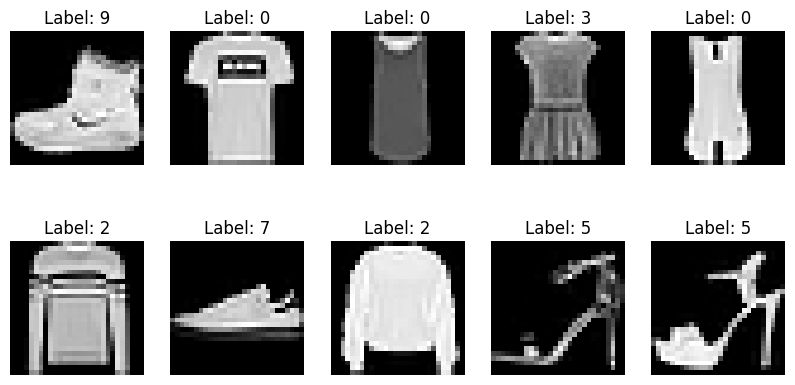

In [132]:
#See Images
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.show()

In [133]:
#Normalize and Verify
X_train=X_train/255.0
X_test=X_test/255.0
print(X_train.max())

1.0


In [134]:
#Reshape
X_train=X_train.reshape(-1,28,28,1)
X_test=X_test.reshape(-1,28,28,1)

In [135]:
#Make Model
model=keras.Sequential([
    layers.Input(shape=(28,28,1)),
    layers.Conv2D(32,(3,3),activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64,(3,3),activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10,activation="softmax")
])

In [136]:
#Compile Model
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [137]:
#Fit Model
history=model.fit(X_train,y_train,epochs=15,validation_split=0.2,batch_size=32)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 54s 35ms/step - accuracy: 0.7919 - loss: 0.5801 - val_accuracy: 0.8537 - val_loss: 0.3845
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 50s 33ms/step - accuracy: 0.8581 - loss: 0.3918 - val_accuracy: 0.8850 - val_loss: 0.3115
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 84s 34ms/step - accuracy: 0.8759 - loss: 0.3434 - val_accuracy: 0.8928 - val_loss: 0.2948
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 81s 34ms/step - accuracy: 0.8883 - loss: 0.3086 - val_accuracy: 0.8906 - val_loss: 0.2935
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 50s 33ms/step - accuracy: 0.8982 - loss: 0.2807 - val_accuracy: 0.9025 - val_loss: 0.2610
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 51s 34ms/step - accuracy: 0.9036 - loss: 0.2644 - val_accuracy: 0.9088 - val_loss: 0.2534
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 81s 33ms/step - accuracy: 0.9089 - loss: 0.2472 - val_accuracy: 0.9007 - val_loss: 0.2612
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 84s 35ms/step - accuracy: 0.9150 -

In [138]:
#Evaluation
#Performance on Unseen Data
test_loss, test_acc = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_acc)
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9115 - loss: 0.2790
Test Accuracy: 0.9114999771118164
Test Loss: 0.27896571159362793


In [139]:
#predictions
y_pred = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step


In [140]:
#Real Predictions
y_pred_classes = np.argmax(y_pred, axis=1)
print(y_pred_classes)

[9 2 1 ... 8 1 5]


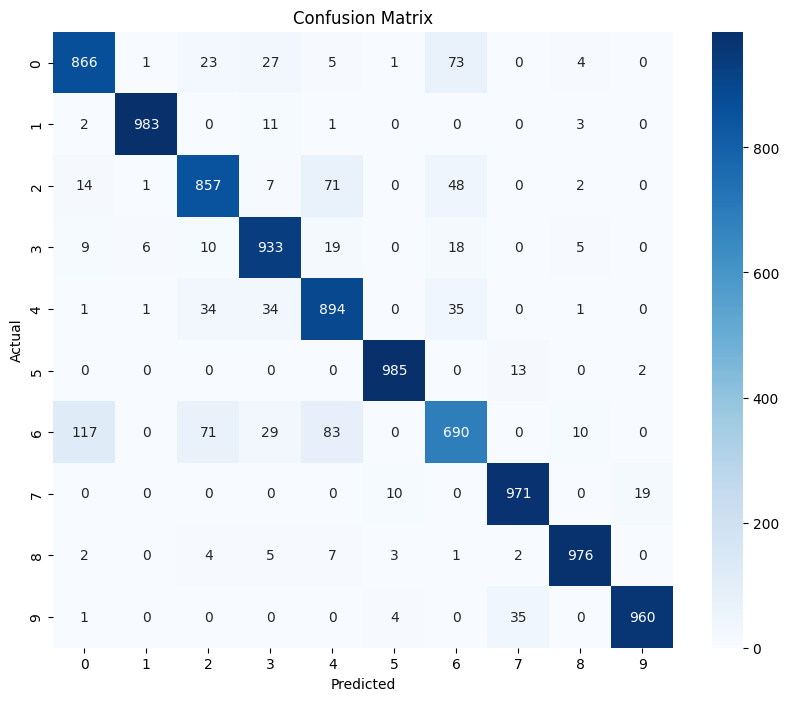

In [141]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compare actual labels (y_test) with predicted labels (y_pred_classes)
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [142]:
#Classification Report
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_classes))

              precision    recall  f1-score   support

           0       0.86      0.87      0.86      1000
           1       0.99      0.98      0.99      1000
           2       0.86      0.86      0.86      1000
           3       0.89      0.93      0.91      1000
           4       0.83      0.89      0.86      1000
           5       0.98      0.98      0.98      1000
           6       0.80      0.69      0.74      1000
           7       0.95      0.97      0.96      1000
           8       0.98      0.98      0.98      1000
           9       0.98      0.96      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



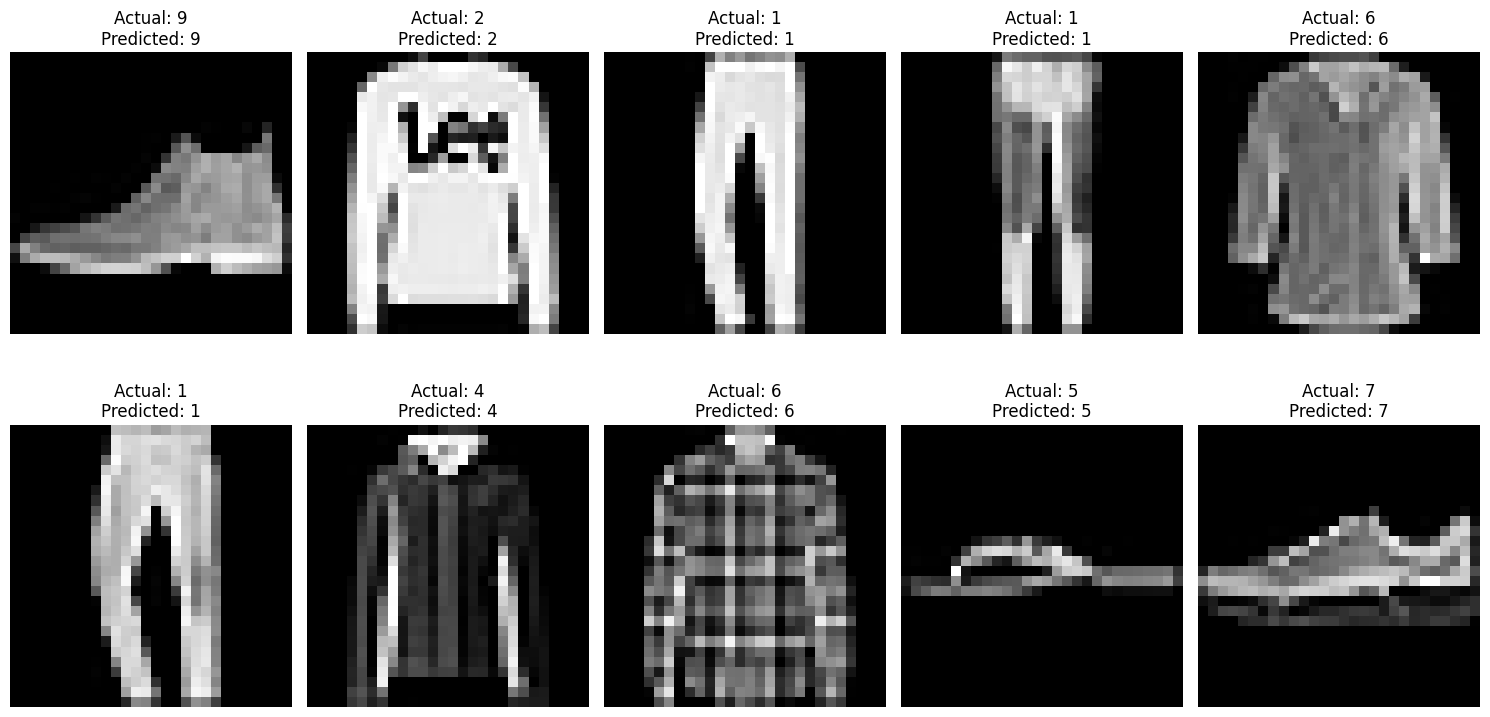

In [143]:
#Actual VS Predicted
plt.figure(figsize=(15, 8))

for i in range(10):
    plt.subplot(2, 5, i+1)

    plt.imshow(X_test[i].squeeze(), cmap='gray')

    plt.title(f"Actual: {y_test[i]}\nPredicted: {y_pred_classes[i]}")

    plt.axis('off')

plt.tight_layout()
plt.show()